# 강판 결함 분류 - 팀 EDA 기반 전처리 (처음부터)

| 단계 | 내용 | 팀 EDA 9장 |
|---|---|---|
| 1 | 라이브러리 / 데이터 불러오기 | - |
| 2 | 데이터 점검 (결측 / 중복 / 정렬 / 강종 관계) | ④ |
| 3 | 정답(y) 만들기 + 입력(X) 정하기 | ① |
| 4 | 강종 A400 한 열로 통일 | ② |
| 5 | 파생 변수 / 중복 변수 세트 | ⑨ ⑪ |
| 6 | Train / Val / Test 분할 | ③ |
| 7 | 전처리기 (이상치 유지 / 표준화 / 로그 변환) | ⑤ ⑥ |
| 8 | 전처리 세트별 성능 비교 | ⑥ ⑨ ⑪ |
| 9 | SMOTENC (강종을 범주형으로) | ⑩ |

## 1. 라이브러리 / 데이터 불러오기

In [1]:
import numpy as np
import pandas as pd
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import f1_score, accuracy_score

pd.set_option("display.max_columns", 50)

In [2]:
try:
    # 방법 A : UCI에서 바로 불러오기
    from ucimlrepo import fetch_ucirepo
    d = fetch_ucirepo(id=198)
    df = pd.concat([d.data.features, d.data.targets], axis=1)
    print("UCI에서 불러옴")
except Exception as e:
    # 방법 B : 내려받은 파일로 불러오기 (Faults.NNA / Faults27x7_var 가 노트북과 같은 폴더에 있어야 함)
    print("UCI 불러오기 실패 -> 로컬 파일 사용:", type(e).__name__)
    with open("Faults27x7_var", "r") as f:
        cols = [line.strip() for line in f if line.strip()]
    df = pd.read_csv("Faults.NNA", sep=r"\s+", header=None, names=cols)

# 열 이름은 출처마다 철자가 다릅니다 (예: K_Scatch / K_Scratch) -> 이름 대신 위치로 나눕니다
FEATURE_COLS = list(df.columns[:27])      # 앞 27개 = 입력 변수
TARGET_COLS  = list(df.columns[27:34])    # 뒤 7개  = 정답 (원-핫)
print(df.shape, "| 입력", len(FEATURE_COLS), "개 | 정답", len(TARGET_COLS), "개")
print("정답 열 :", TARGET_COLS)

# 이후 코드에서 이름으로 쓰는 변수가 모두 있는지 확인
need = ["TypeOfSteel_A300", "TypeOfSteel_A400", "Steel_Plate_Thickness", "Maximum_of_Luminosity",
        "Minimum_of_Luminosity", "Y_Maximum", "X_Maximum", "Sum_of_Luminosity", "Square_Index",
        "Outside_Global_Index", "X_Perimeter", "Y_Perimeter", "Pixels_Areas", "Outside_X_Index"]
print("없는 변수 :", [c for c in need if c not in FEATURE_COLS])   # [] 이면 정상
df.head()

UCI에서 불러옴
(1941, 34) | 입력 27 개 | 정답 7 개
정답 열 : ['Pastry', 'Z_Scratch', 'K_Scratch', 'Stains', 'Dirtiness', 'Bumps', 'Other_Faults']
없는 변수 : []


,X_Minimum,X_Maximum,Y_Minimum,Y_Maximum,Pixels_Areas,X_Perimeter,Y_Perimeter,Sum_of_Luminosity,Maximum_of_Luminosity,Length_of_Conveyer,TypeOfSteel_A300,TypeOfSteel_A400,Steel_Plate_Thickness,Edges_Index,Empty_Index,Square_Index,Outside_X_Index,Edges_X_Index,Edges_Y_Index,Outside_Global_Index,LogOfAreas,Log_X_Index,Log_Y_Index,Orientation_Index,Luminosity_Index,SigmoidOfAreas,Minimum_of_Luminosity,Pastry,Z_Scratch,K_Scratch,Stains,Dirtiness,Bumps,Other_Faults
0,42,50,270900,270944,267,17,44,24220,108,1687,1,0,80,0.0498,0.2415,0.1818,0.0047,0.4706,1.0000,1.0,2.4265,0.9031,1.6435,0.8182,-0.2913,0.5822,76,1,0,0,0,0,0,0
1,645,651,2538079,2538108,108,10,30,11397,123,1687,1,0,80,0.7647,0.3793,0.2069,0.0036,0.6000,0.9667,1.0,2.0334,0.7782,1.4624,0.7931,-0.1756,0.2984,84,1,0,0,0,0,0,0
2,829,835,1553913,1553931,71,8,19,7972,125,1623,1,0,100,0.9710,0.3426,0.3333,0.0037,0.7500,0.9474,1.0,1.8513,0.7782,1.2553,0.6667,-0.1228,0.2150,99,1,0,0,0,0,0,0
3,853,860,369370,369415,176,13,45,18996,126,1353,0,1,290,0.7287,0.4413,0.1556,0.0052,0.5385,1.0000,1.0,2.2455,0.8451,1.6532,0.8444,-0.1568,0.5212,99,1,0,0,0,0,0,0
4,1289,1306,498078,498335,2409,60,260,246930,126,1353,0,1,185,0.0695,0.4486,0.0662,0.0126,0.2833,0.9885,1.0,3.3818,1.2305,2.4099,0.9338,-0.1992,1.0000,37,1,0,0,0,0,0,0


## 2. 데이터 점검 - EDA 결론이 맞는지 확인

In [3]:
print("결측치 :", df.isna().sum().sum())          # 0 이면 결측 처리 불필요
print("중복 행 :", df.duplicated().sum())

# 정답 열은 행마다 정확히 1개만 1이어야 함 (다중 레이블이 아닌 7-클래스 분류)
print("정답 합이 1이 아닌 행 :", (df[TARGET_COLS].sum(axis=1) != 1).sum())

# 강종 A300 / A400 은 서로 반대 값 (A400 = 1 - A300)
print("A300 + A400 == 1 :", ((df["TypeOfSteel_A300"] + df["TypeOfSteel_A400"]) == 1).all())
print(df[["TypeOfSteel_A300", "TypeOfSteel_A400"]].sum().to_dict())

결측치 : 0
중복 행 : 0
정답 합이 1이 아닌 행 : 0
A300 + A400 == 1 : True
{'TypeOfSteel_A300': 777, 'TypeOfSteel_A400': 1164}


In [4]:
# 데이터가 결함 유형별로 정렬돼 있는지 확인 -> 그대로 자르면 안 되고 stratify 분할이 필요
order = df[TARGET_COLS].idxmax(axis=1)
print("연속 구간 수 (7이면 완전 정렬) :", (order != order.shift()).sum())
order.value_counts()

연속 구간 수 (7이면 완전 정렬) : 7


Other_Faults    673
Bumps           402
K_Scratch       391
Z_Scratch       190
Pastry          158
Stains           72
Dirtiness        55
Name: count, dtype: int64

## 3. 정답(y)과 입력(X) 만들기
- 정답 원-핫 7열 -> 결함 이름 한 열 -> 숫자 라벨
- 정답 7열은 X에 넣지 않음 (넣으면 정답을 미리 보는 데이터 누수)

In [5]:
fault_type = df[TARGET_COLS].idxmax(axis=1)         # 7열 -> 결함 이름
le = LabelEncoder()
y = le.fit_transform(fault_type)                    # 알파벳 순 : Bumps 0 ... Z_Scratch 6
print(dict(zip(le.classes_, range(len(le.classes_)))))

X = df[FEATURE_COLS].copy()
print("X :", X.shape, "| y :", y.shape)
pd.Series(fault_type).value_counts()

{'Bumps': 0, 'Dirtiness': 1, 'K_Scratch': 2, 'Other_Faults': 3, 'Pastry': 4, 'Stains': 5, 'Z_Scratch': 6}
X : (1941, 27) | y : (1941,)


Other_Faults    673
Bumps           402
K_Scratch       391
Z_Scratch       190
Pastry          158
Stains           72
Dirtiness        55
Name: count, dtype: int64

## 4. 강종 통일 (EDA 9장 ②)
A300과 A400은 정보가 같으므로 **`TypeOfSteel_A400` 한 열만 사용 (1 = A400 / 0 = A300) 입력 27개 -> 26개

In [6]:
X = X.drop(columns="TypeOfSteel_A300")
print("입력 변수 수 :", X.shape[1])

입력 변수 수 : 26


## 5. 파생 변수 / 중복 변수 세트 (EDA 9장 ⑨ ⑪)
- **중복 변수** : 상관 0.98 이상인 쌍의 한쪽과 같은 정보를 담은 방향 지표를 제거한 세트를 따로 만들어 비교
- **파생 변수** : 밝기 범위(`Maximum - Minimum`)와 두께 구간(40 / 41~70 / 71~100 / 101~300)
- 이상치는 실제 결함 신호이므로 제거하지 않음

In [7]:
REDUNDANT_DROP = ["Y_Maximum", "X_Maximum", "Sum_of_Luminosity",   # Y_Minimum / X_Minimum / Pixels_Areas 와 거의 같은 정보
                  "Square_Index", "Outside_Global_Index"]          # Orientation_Index 하나만 유지
LOG_COLS = ["X_Perimeter", "Y_Perimeter", "Sum_of_Luminosity", "Pixels_Areas", "Outside_X_Index"]  # 치우침이 큰 변수
BIN_COLS = ["TypeOfSteel_A400", "Thickness_Bin"]                   # 0/1 또는 구간 번호 -> 표준화하지 않음

def add_derived(X):
    X = X.copy()
    X["Luminosity_Range"] = X["Maximum_of_Luminosity"] - X["Minimum_of_Luminosity"]
    X["Thickness_Bin"] = pd.cut(X["Steel_Plate_Thickness"], bins=[0, 40, 70, 100, 300], labels=False).astype(int)
    return X

def make_xy(drop_redundant=False, derived=False):
    Xs = add_derived(X) if derived else X.copy()
    if drop_redundant:
        Xs = Xs.drop(columns=[c for c in REDUNDANT_DROP if c in Xs.columns])
    return Xs

for name, kw in [("기본", {}), ("중복제거", dict(drop_redundant=True)),
                 ("파생추가", dict(derived=True)), ("중복제거+파생", dict(drop_redundant=True, derived=True))]:
    print(f"{name:10s} 입력 {make_xy(**kw).shape[1]}개")

기본         입력 26개
중복제거       입력 21개
파생추가       입력 28개
중복제거+파생    입력 23개


## 6. Train / Val / Test 분할 (EDA 9장 ③)
데이터가 유형별로 정렬돼 있으므로 `stratify=y` + 고정 `random_state=42` -> 60 / 20 / 20.

In [8]:
def split(Xs):
    X_tmp, X_test, y_tmp, y_test = train_test_split(Xs, y, test_size=0.2, stratify=y, random_state=42)
    X_train, X_val, y_train, y_val = train_test_split(X_tmp, y_tmp, test_size=0.25, stratify=y_tmp, random_state=42)
    return X_train, X_val, X_test, y_train, y_val, y_test

X_train, X_val, X_test, y_train, y_val, y_test = split(make_xy())
print("Train", X_train.shape, "/ Val", X_val.shape, "/ Test", X_test.shape)

# 클래스 비율이 세 데이터에서 비슷한지 확인
pd.DataFrame({"Train": np.bincount(y_train) / len(y_train),
              "Val":   np.bincount(y_val) / len(y_val),
              "Test":  np.bincount(y_test) / len(y_test)}, index=le.classes_).round(3)

Train (1164, 26) / Val (388, 26) / Test (389, 26)


,Train,Val,Test
Bumps,0.207,0.206,0.208
Dirtiness,0.028,0.028,0.028
K_Scratch,0.202,0.201,0.201
Other_Faults,0.347,0.345,0.347
Pastry,0.081,0.082,0.082
Stains,0.037,0.039,0.036
Z_Scratch,0.098,0.098,0.098


## 7. 전처리기 (EDA 9장 ⑤ ⑥)
- 결측 처리 없음 / 이상치 제거 없음
- **표준화는 Train으로만 fit** -> `Pipeline` 안에 넣어 Val / Test 에는 자동으로 transform 만 적용
- 로그 변환(`log1p`)은 선택 사항으로 LR 에서만 비교 (트리 모델은 값의 순서만 보므로 변환 효과 없음)
- 범주형 열(강종 / 두께 구간)은 **맨 뒤**에 두어 9장의 SMOTENC 인덱스 계산에 사용

In [9]:
def make_prep(cols, scale=True, log=False):
    cols = list(cols)
    cat  = [c for c in BIN_COLS if c in cols]
    num  = [c for c in cols if c not in cat]
    logc = [c for c in LOG_COLS if c in num] if log else []
    rest = [c for c in num if c not in logc]
    steps = []
    if logc:
        steps.append(("log", Pipeline([("f", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                                       ("s", StandardScaler())]), logc))
    if rest:
        steps.append(("num", StandardScaler() if scale else "passthrough", rest))
    steps.append(("cat", "passthrough", cat))
    return ColumnTransformer(steps), len(cat)

# 전처리 결과 확인 : Train 평균 0 / 표준편차 1 이어야 함
prep, n_cat = make_prep(X_train.columns, scale=True)
Z_train = prep.fit_transform(X_train)
print("Train 평균(최대 절댓값) :", np.abs(Z_train[:, :-n_cat].mean(axis=0)).max().round(6))
print("Train 표준편차(범위)   :", Z_train[:, :-n_cat].std(axis=0).min().round(3), "~", Z_train[:, :-n_cat].std(axis=0).max().round(3))
print("Val 평균(참고)         :", prep.transform(X_val)[:, :-n_cat].mean(axis=0).round(2)[:5], "... (0 에서 약간 벗어나는 것이 정상)")

Train 평균(최대 절댓값) : 0.0
Train 표준편차(범위)   : 1.0 ~ 1.0
Val 평균(참고)         : [-0.04 -0.05 -0.12 -0.12 -0.04] ... (0 에서 약간 벗어나는 것이 정상)


## 8. 전처리 세트별 성능 비교 (Val Macro F1)

In [10]:
MODELS = {
    "LR": (lambda: LogisticRegression(max_iter=3000, random_state=42), True),     # (모델 생성 함수, 표준화 여부)
    "RF": (lambda: RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1), False),
    "GB": (lambda: GradientBoostingClassifier(random_state=42), False),
}

def run(model, drop_redundant=False, derived=False, log=False):
    Xs = make_xy(drop_redundant, derived)
    X_tr, X_va, X_te, y_tr, y_va, y_te = split(Xs)
    mk, scale = MODELS[model]
    prep, _ = make_prep(Xs.columns, scale=scale, log=log)
    pipe = Pipeline([("prep", prep), ("clf", mk())]).fit(X_tr, y_tr)
    p = pipe.predict(X_va)
    return Xs.shape[1], f1_score(y_va, p, average="macro"), accuracy_score(y_va, p)

settings = [("① 26개 기본", {}),
            ("② +로그변환(LR용)", dict(log=True)),
            ("③ 중복제거", dict(drop_redundant=True)),
            ("④ +파생변수", dict(derived=True)),
            ("⑤ 중복제거+파생", dict(drop_redundant=True, derived=True))]
rows = []
for name, kw in settings:
    for m in MODELS:
        if kw.get("log") and m != "LR":      # 로그 변환은 LR 만
            continue
        n, f1, acc = run(m, **kw)
        rows.append((name, m, n, round(f1, 4), round(acc, 4)))
result = pd.DataFrame(rows, columns=["세트", "모델", "입력수", "Val MacroF1", "Val Acc"])
result

,세트,모델,입력수,Val MacroF1,Val Acc
0,① 26개 기본,LR,26,0.7270,0.7320
1,① 26개 기본,RF,26,0.7915,0.7809
2,① 26개 기본,GB,26,0.7861,0.7887
3,② +로그변환(LR용),LR,26,0.7296,0.7371
4,③ 중복제거,LR,21,0.7218,0.7216
5,③ 중복제거,RF,21,0.7832,0.7706
6,③ 중복제거,GB,21,0.7862,0.7861
7,④ +파생변수,LR,28,0.7328,0.7371
8,④ +파생변수,RF,28,0.8081,0.7938
9,④ +파생변수,GB,28,0.7784,0.7887


In [11]:
# 보기 쉽게 모델별 열로 펼치기
result.pivot(index="세트", columns="모델", values="Val MacroF1")

모델,GB,LR,RF
세트,,,
① 26개 기본,0.7861,0.7270,0.7915
② +로그변환(LR용),NaN,0.7296,NaN
③ 중복제거,0.7862,0.7218,0.7832
④ +파생변수,0.7784,0.7328,0.8081
⑤ 중복제거+파생,0.7806,0.6828,0.7922


## 9. SMOTENC (EDA 9장 ⑩)
강종은 0/1 범주형이므로 일반 SMOTE 대신 SMOTENC 를 사용함. `imblearn` 의 Pipeline 을 쓰면 오버샘플링이 fit 시점(Train)에만 적용돼 Val / Test 로 새지 않음.

In [12]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTENC

Xs = make_xy()
X_tr, X_va, X_te, y_tr, y_va, y_te = split(Xs)
prep, n_cat = make_prep(Xs.columns, scale=True)
cat_idx = list(range(Xs.shape[1] - n_cat, Xs.shape[1]))      # 전처리 후 맨 뒤 열 = 강종

smote_pipe = ImbPipeline([
    ("prep", prep),
    ("smote", SMOTENC(categorical_features=cat_idx, random_state=42)),
    ("clf", GradientBoostingClassifier(random_state=42)),
]).fit(X_tr, y_tr)

p = smote_pipe.predict(X_va)
print("GB + SMOTENC  Val Macro F1 :", round(f1_score(y_va, p, average="macro"), 4),
      "/ Acc :", round(accuracy_score(y_va, p), 4))

GB + SMOTENC  Val Macro F1 : 0.799 / Acc : 0.7809


---
# 클래스 불균형 처리 + 모델별 평가

| 단계 | 내용 |
|---|---|
| 10 | 3일차 준비 (도구 불러오기 / 사용할 입력 세트 고르기) |
| 11 | 불균형 처리 3가지 전/후 클래스 개수 확인 |
| 12 | 모델 + 처리 방법 조합을 만드는 함수 |
| 13 | 4개 모델 × 4가지 방법 = 16개 조합 학습 / Val 평가 |
| 14 | 결과 표 + 히트맵 (Macro F1) |
| 15 | 소수 클래스 Recall 비교 |
| 16 | Val 최고 조합 선정 + Test 평가 (한 번만) |
| 17 | 결과 저장 |

**지켜야 할 규칙**
- 샘플링(RUS / SMOTE)은 **Train에만** 적용함 (`imblearn` Pipeline이 fit 때만 적용).
- GradientBoosting 은 `class_weight` 옵션이 없어서 `sample_weight` 로 같은 효과를 냄.
- 주 평가 지표는 Macro F1 (Accuracy / 클래스별 P·R·F1 / 혼동행렬 보조).

## 10. 3일차 준비

In [13]:
import time
import matplotlib.pyplot as plt
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import SMOTENC
from sklearn.tree import DecisionTreeClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             recall_score, precision_score)

# 한글이 네모(□)로 깨질 때를 대비한 글꼴 설정 (설치된 것을 자동으로 사용)
from matplotlib import font_manager
for f in ["Malgun Gothic", "AppleGothic", "NanumGothic", "Noto Sans CJK KR"]:
    if f in {x.name for x in font_manager.fontManager.ttflist}:
        plt.rcParams["font.family"] = f
        break
plt.rcParams["axes.unicode_minus"] = False

# ★ 3일차에 사용할 입력 세트 (필요하면 바꾸세요)
#   {}                                  : 26개 기본 (강종 A400 통일)
#   dict(drop_redundant=True)           : 중복 변수 제거 (21개)
#   dict(derived=True)                  : 파생 변수 추가 (28개)
FEATURE_SET = {}

Xs = make_xy(**FEATURE_SET)
X_tr, X_va, X_te, y_tr, y_va, y_te = split(Xs)
CLASSES = list(le.classes_)
print("입력 변수 :", Xs.shape[1], "개 | Train", X_tr.shape, "/ Val", X_va.shape, "/ Test", X_te.shape)

입력 변수 : 26 개 | Train (1164, 26) / Val (388, 26) / Test (389, 26)


## 11. 불균형 처리 3가지 - 전/후 클래스 개수
- **Class Weight** : 데이터 개수는 그대로 두고 적은 클래스의 오답에 더 큰 벌점을 줌.
- **RUS (Random Under Sampling)** : 많은 클래스를 가장 적은 클래스 수준으로 줄임.
- **SMOTE** : 적은 클래스의 가짜 샘플을 만들어 늘림 (강종이 범주형이라 SMOTENC 사용, 거리 기반이라 표준화 필요).

In [14]:
# RUS 후 개수
_, y_rus = RandomUnderSampler(random_state=42).fit_resample(X_tr, y_tr)

# SMOTENC 후 개수 (표준화한 뒤 적용 / 범주형 열은 맨 뒤)
prep_tmp, n_cat = make_prep(Xs.columns, scale=True)
cat_idx = list(range(Xs.shape[1] - n_cat, Xs.shape[1]))
Z_tr = prep_tmp.fit_transform(X_tr)
_, y_smote = SMOTENC(categorical_features=cat_idx, random_state=42).fit_resample(Z_tr, y_tr)

dist = pd.DataFrame({"원본 Train": np.bincount(y_tr),
                     "RUS 후": np.bincount(y_rus),
                     "SMOTE 후": np.bincount(y_smote)}, index=CLASSES)
dist.loc["합계"] = dist.sum()
dist

,원본 Train,RUS 후,SMOTE 후
Bumps,241,33,404
Dirtiness,33,33,404
K_Scratch,235,33,404
Other_Faults,404,33,404
Pastry,94,33,404
Stains,43,33,404
Z_Scratch,114,33,404
합계,1164,231,2828


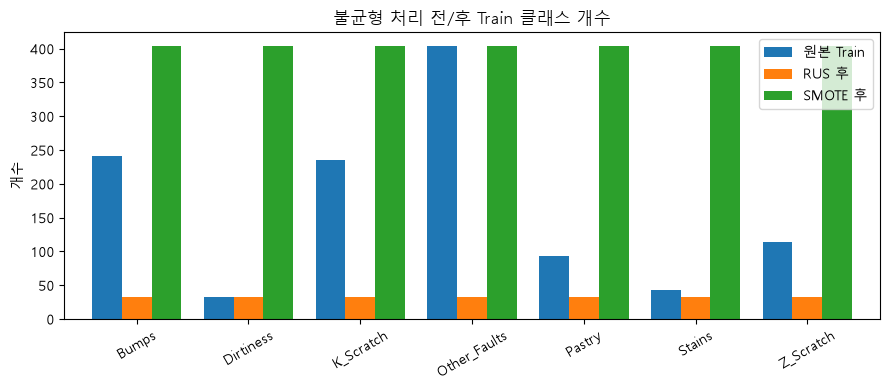

In [15]:
# 막대그래프로 보기
dist.drop(index="합계").plot(kind="bar", figsize=(9, 4), width=0.8)
plt.title("불균형 처리 전/후 Train 클래스 개수")
plt.ylabel("개수")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## 12. 모델 + 처리 방법 조합 함수
- `build(모델, 방법)` : 전처리 → (샘플링) → 모델 순서의 파이프라인을 만듦.
- 방법 이름 : `Baseline`(처리 없음) / `ClassWeight` / `RUS` / `SMOTE`
- 표준화는 LR 이거나 SMOTE 일 때만 함 (트리 모델은 값의 크기가 영향을 주지 않음).

In [16]:
MODEL_NAMES = ["LR", "DT", "RF", "GB"]
METHODS = ["Baseline", "ClassWeight", "RUS", "SMOTE"]

def make_clf(mn, method):
    cw = "balanced" if method == "ClassWeight" else None     # GB 는 class_weight 옵션이 없음
    if mn == "LR": return LogisticRegression(max_iter=3000, class_weight=cw, random_state=42)
    if mn == "DT": return DecisionTreeClassifier(class_weight=cw, random_state=42)
    if mn == "RF": return RandomForestClassifier(n_estimators=300, class_weight=cw, random_state=42, n_jobs=-1)
    if mn == "GB": return GradientBoostingClassifier(random_state=42)

def build(mn, method):
    scale = (mn == "LR") or (method == "SMOTE")
    prep, n_cat = make_prep(Xs.columns, scale=scale)
    steps = [("prep", prep)]
    if method == "RUS":
        steps.append(("rus", RandomUnderSampler(random_state=42)))
    if method == "SMOTE":
        ci = list(range(Xs.shape[1] - n_cat, Xs.shape[1]))
        steps.append(("smote", SMOTENC(categorical_features=ci, random_state=42)))
    steps.append(("clf", make_clf(mn, method)))
    return ImbPipeline(steps)

def fit_model(pipe, mn, method, X, y):
    if mn == "GB" and method == "ClassWeight":
        # GB 의 Class Weight : 샘플마다 가중치(적은 클래스일수록 큼)를 줘서 학습
        sw = compute_sample_weight("balanced", y)
        pipe.fit(X, y, clf__sample_weight=sw)
    else:
        pipe.fit(X, y)
    return pipe

# 동작 확인 : GB + ClassWeight 가중치가 적은 클래스에 더 크게 붙는지
sw = compute_sample_weight("balanced", y_tr)
print(pd.Series(sw).groupby(y_tr).first().rename(index=dict(enumerate(CLASSES))).round(2))

Bumps           0.69
Dirtiness       5.04
K_Scratch       0.71
Other_Faults    0.41
Pastry          1.77
Stains          3.87
Z_Scratch       1.46
dtype: float64


## 13. 16개 조합 학습 + Val 평가

In [17]:
results, store = [], {}
for mn in MODEL_NAMES:
    for method in METHODS:
        t0 = time.time()
        pipe = fit_model(build(mn, method), mn, method, X_tr, y_tr)
        pred = pipe.predict(X_va)
        store[(mn, method)] = (pipe, pred)
        rec = recall_score(y_va, pred, average=None, labels=range(len(CLASSES)))
        results.append({"모델": mn, "방법": method,
                        "Macro F1": f1_score(y_va, pred, average="macro"),
                        "Accuracy": accuracy_score(y_va, pred),
                        **{f"Recall_{c}": r for c, r in zip(CLASSES, rec)},
                        "시간(초)": time.time() - t0})
        print(f"{mn:3s} {method:12s} Macro F1 {results[-1]['Macro F1']:.4f}  ({results[-1]['시간(초)']:.1f}초)")
res = pd.DataFrame(results)

LR  Baseline     Macro F1 0.7270  (0.0초)
LR  ClassWeight  Macro F1 0.6673  (0.0초)
LR  RUS          Macro F1 0.6131  (0.0초)
LR  SMOTE        Macro F1 0.6714  (0.1초)
DT  Baseline     Macro F1 0.7261  (0.0초)
DT  ClassWeight  Macro F1 0.6930  (0.0초)
DT  RUS          Macro F1 0.5197  (0.0초)
DT  SMOTE        Macro F1 0.6819  (0.1초)
RF  Baseline     Macro F1 0.7915  (0.3초)
RF  ClassWeight  Macro F1 0.8195  (0.3초)
RF  RUS          Macro F1 0.6349  (0.2초)
RF  SMOTE        Macro F1 0.8097  (0.3초)
GB  Baseline     Macro F1 0.7861  (2.2초)
GB  ClassWeight  Macro F1 0.8037  (2.2초)
GB  RUS          Macro F1 0.6583  (0.5초)
GB  SMOTE        Macro F1 0.7990  (6.0초)


## 14. 결과 표 + 히트맵 (Val Macro F1)

In [18]:
pv = res.pivot(index="모델", columns="방법", values="Macro F1").loc[MODEL_NAMES, METHODS]
display(pv.round(4))

# Baseline 대비 변화량 (+ 이면 좋아진 것)
diff = pv.sub(pv["Baseline"], axis=0).drop(columns="Baseline")
print("Baseline 대비 Macro F1 변화량")
display(diff.round(4))

방법,Baseline,ClassWeight,RUS,SMOTE
모델,,,,
LR,0.7270,0.6673,0.6131,0.6714
DT,0.7261,0.6930,0.5197,0.6819
RF,0.7915,0.8195,0.6349,0.8097
GB,0.7861,0.8037,0.6583,0.7990


Baseline 대비 Macro F1 변화량


방법,ClassWeight,RUS,SMOTE
모델,,,
LR,-0.0597,-0.1139,-0.0556
DT,-0.0331,-0.2064,-0.0442
RF,0.0281,-0.1566,0.0182
GB,0.0175,-0.1278,0.0129


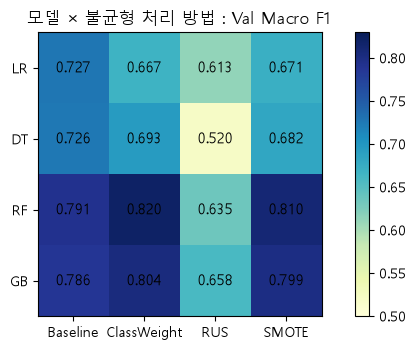

In [19]:
fig, ax = plt.subplots(figsize=(7, 3.6))
im = ax.imshow(pv.values, cmap="YlGnBu", vmin=pv.values.min() - 0.02, vmax=pv.values.max() + 0.01)
ax.set_xticks(range(len(METHODS))); ax.set_xticklabels(METHODS)
ax.set_yticks(range(len(MODEL_NAMES))); ax.set_yticklabels(MODEL_NAMES)
for i in range(pv.shape[0]):
    for j in range(pv.shape[1]):
        ax.text(j, i, f"{pv.values[i, j]:.3f}", ha="center", va="center", fontsize=11)
ax.set_title("모델 × 불균형 처리 방법 : Val Macro F1")
plt.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

## 15. 소수 클래스 Recall 비교
Recall = 실제 그 결함인 것 중 모델이 찾아낸 비율. 개수가 적은 Dirtiness / Stains / Pastry 를 불균형 처리가 얼마나 살렸는지 확인.

In [20]:
minor = ["Dirtiness", "Stains", "Pastry"]
rec_tbl = res.set_index(["모델", "방법"])[[f"Recall_{c}" for c in minor]]
rec_tbl.columns = minor
display(rec_tbl.round(3))

# 방법별 평균 (4개 모델 평균)
print("방법별 평균 Recall")
display(rec_tbl.groupby(level="방법").mean().loc[METHODS].round(3))

Dirtiness  Stains  Pastry
모델 방법                                    
LR Baseline         0.364   1.000   0.562
   ClassWeight      0.636   1.000   0.781
   RUS              0.636   1.000   0.656
   SMOTE            0.545   1.000   0.750
DT Baseline         0.545   0.933   0.500
   ClassWeight      0.636   0.933   0.469
   RUS              0.818   1.000   0.219
   SMOTE            0.455   1.000   0.594
RF Baseline         0.636   0.933   0.562
   ClassWeight      0.727   1.000   0.844
   RUS              0.818   1.000   0.594
   SMOTE            0.727   1.000   0.812
GB Baseline         0.455   1.000   0.594
   ClassWeight      0.727   1.000   0.656
   RUS              0.818   1.000   0.500
   SMOTE            0.636   1.000   0.812

방법별 평균 Recall


,Dirtiness,Stains,Pastry
방법,,,
Baseline,0.500,0.967,0.555
ClassWeight,0.682,0.983,0.688
RUS,0.773,1.000,0.492
SMOTE,0.591,1.000,0.742


## 16. Val 최고 조합 선정 + Test 평가 (한 번만)
Val Macro F1 이 가장 높은 조합을 고르고 Test 는 여기서 딱 한 번만 사용함. 같은 모델의 Baseline 과도 함께 비교해 불균형 처리가 Test 에서도 도움이 됐는지 확인.

In [21]:
best = res.sort_values("Macro F1", ascending=False).iloc[0]
bm, bmethod = best["모델"], best["방법"]
print(f"Val 최고 조합 : {bm} + {bmethod}  (Val Macro F1 {best['Macro F1']:.4f})")

def test_eval(mn, method):
    pipe = store[(mn, method)][0]        # Train 으로 학습해 둔 모델 그대로 사용
    p = pipe.predict(X_te)
    return p, f1_score(y_te, p, average="macro"), accuracy_score(y_te, p)

p_best, f1_best, acc_best = test_eval(bm, bmethod)
p_base, f1_base, acc_base = test_eval(bm, "Baseline")
display(pd.DataFrame({"Macro F1": [f1_base, f1_best], "Accuracy": [acc_base, acc_best]},
                     index=[f"{bm} Baseline", f"{bm} + {bmethod}"]).round(4))

Val 최고 조합 : RF + ClassWeight  (Val Macro F1 0.8195)


,Macro F1,Accuracy
RF Baseline,0.7962,0.7892
RF + ClassWeight,0.7838,0.7532


              precision    recall  f1-score   support

       Bumps      0.619     0.741     0.674        81
   Dirtiness      0.818     0.818     0.818        11
   K_Scratch      0.949     0.949     0.949        78
Other_Faults      0.748     0.615     0.675       135
      Pastry      0.523     0.719     0.605        32
      Stains      0.923     0.857     0.889        14
   Z_Scratch      0.914     0.842     0.877        38

    accuracy                          0.753       389
   macro avg      0.785     0.791     0.784       389
weighted avg      0.767     0.753     0.755       389



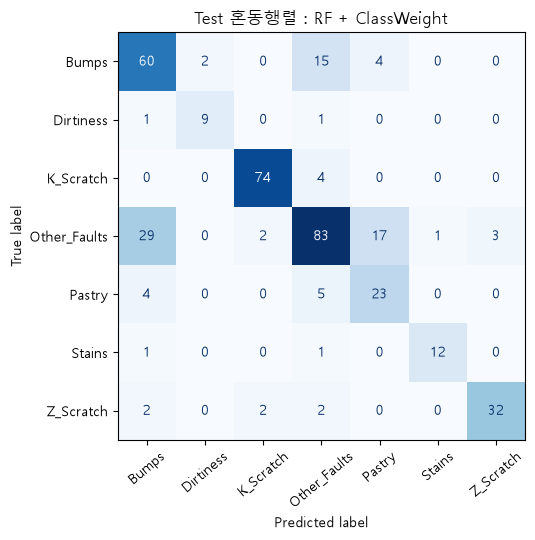

In [22]:
print(classification_report(y_te, p_best, target_names=CLASSES, digits=3))

cm = confusion_matrix(y_te, p_best)
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(ax=ax, cmap="Blues", colorbar=False, xticks_rotation=40)
ax.set_title(f"Test 혼동행렬 : {bm} + {bmethod}")
plt.tight_layout()
plt.show()

---
# 처리 전후 비교 / 모델 개선 / 최종 모델 / 대시보드 준비
이전의 `build` / `fit_model` / `make_clf` 와 전처리 함수를 이어서 씀.

| 단계 | 내용 |
|---|---|
| 18 | 개발 데이터(Train+Val) 5-fold CV 준비 |
| 19 | 16개 조합 CV 평가 (처리 전후 비교표) |
| 20 | 처리 전후 비교 / Trade-off 그림 |
| 21 | 하이퍼파라미터 튜닝 (CV 1위 조합) |
| 22 | 최종 모델 학습 + Test 평가 (한 번만) |
| 23 | 최종 모델 시각화 (혼동행렬 / 변수 중요도) |
| 24 | 대시보드용 CSV 저장 |

**왜 CV를 쓰나요?** 이전처럼 Val 한 번만 보면 우연의 영향이 큽니다 (Dirtiness 는 Val에 11개뿐). Train+Val 1552개를 5등분해 5번 평가하면 평균과 흔들림(표준편차)을 함께 볼 수 있음. **Test 389개는 마지막에 한 번만** 씀.

## 18. 개발 데이터 + 5-fold 교차검증 준비

In [23]:
from sklearn.model_selection import StratifiedKFold, ParameterGrid

# 개발 데이터 = Train + Val  (Test 는 마지막까지 보관)
X_dev = pd.concat([X_tr, X_va])
y_dev = np.concatenate([y_tr, y_va])
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)    # 클래스 비율을 유지하며 5등분
print("개발 데이터 :", X_dev.shape, "/ Test :", X_te.shape)

def build_p(mn, method, params=None):
    """3일차 build 에 하이퍼파라미터(params)를 붙인 버전"""
    pipe = build(mn, method)
    if params:
        pipe.set_params(**{f"clf__{k}": v for k, v in params.items()})
    return pipe

def cv_eval(mn, method, params=None):
    """5-fold CV : 폴드마다 (샘플링 포함) 새로 학습해서 폴드의 검증 부분만 평가"""
    oof = np.zeros(len(y_dev), dtype=int)        # 각 샘플의 '검증 때 예측값'을 모아 둠
    f1s, t0 = [], time.time()
    for tr_idx, va_idx in skf.split(X_dev, y_dev):
        pipe = fit_model(build_p(mn, method, params), mn, method, X_dev.iloc[tr_idx], y_dev[tr_idx])
        p = pipe.predict(X_dev.iloc[va_idx])
        oof[va_idx] = p
        f1s.append(f1_score(y_dev[va_idx], p, average="macro"))
    rec = recall_score(y_dev, oof, average=None, zero_division=0)
    return {"모델": mn, "방법": method,
            "CV Macro F1": np.mean(f1s), "CV 표준편차": np.std(f1s),
            "CV Accuracy": accuracy_score(y_dev, oof),
            "Dirtiness Recall": rec[CLASSES.index("Dirtiness")],
            "Pastry Recall": rec[CLASSES.index("Pastry")],
            "학습시간(초/fold)": (time.time() - t0) / 5}

개발 데이터 : (1552, 26) / Test : (389, 26)


## 19. 16개 조합 CV 평가 (처리 전후 비교)
4개 모델 × 4방법을 5-fold CV 로 평가함. `Baseline` 이 **처리 전**, 나머지 3개가 **처리 후**.

In [24]:
cv_rows = []
for mn in MODEL_NAMES:
    for method in METHODS:
        cv_rows.append(cv_eval(mn, method))
        print(f"{mn:3s} {method:12s} CV Macro F1 {cv_rows[-1]['CV Macro F1']:.4f}", flush=True)
cv = pd.DataFrame(cv_rows)
display(cv.round(4))

LR  Baseline     CV Macro F1 0.7150
LR  ClassWeight  CV Macro F1 0.6641
LR  RUS          CV Macro F1 0.6133
LR  SMOTE        CV Macro F1 0.6783
DT  Baseline     CV Macro F1 0.7194
DT  ClassWeight  CV Macro F1 0.7042
DT  RUS          CV Macro F1 0.5499
DT  SMOTE        CV Macro F1 0.6856
RF  Baseline     CV Macro F1 0.7852
RF  ClassWeight  CV Macro F1 0.7917
RF  RUS          CV Macro F1 0.6643
RF  SMOTE        CV Macro F1 0.7926
GB  Baseline     CV Macro F1 0.8009
GB  ClassWeight  CV Macro F1 0.8044
GB  RUS          CV Macro F1 0.6679
GB  SMOTE        CV Macro F1 0.7980


,모델,방법,CV Macro F1,CV 표준편차,CV Accuracy,Dirtiness Recall,Pastry Recall,학습시간(초/fold)
0,LR,Baseline,0.7150,0.0271,0.7055,0.5682,0.5159,0.0427
1,LR,ClassWeight,0.6641,0.0168,0.6617,0.8182,0.7222,0.0363
2,LR,RUS,0.6133,0.0314,0.6076,0.8409,0.6746,0.0167
3,LR,SMOTE,0.6783,0.0196,0.6701,0.7955,0.7222,0.0911
4,DT,Baseline,0.7194,0.0374,0.7184,0.6364,0.4524,0.0149
5,DT,ClassWeight,0.7042,0.0278,0.7010,0.6364,0.4603,0.0162
6,DT,RUS,0.5499,0.0220,0.5490,0.7500,0.4683,0.0071
7,DT,SMOTE,0.6856,0.0546,0.6778,0.6364,0.4762,0.0590
8,RF,Baseline,0.7852,0.0236,0.7655,0.8182,0.5000,0.2746
9,RF,ClassWeight,0.7917,0.0174,0.7680,0.8182,0.7460,0.3001


## 20. 처리 전후 비교 + Trade-off

In [25]:
cv_pv = cv.pivot(index="모델", columns="방법", values="CV Macro F1").loc[MODEL_NAMES, METHODS]
print("5-fold CV Macro F1")
display(cv_pv.round(4))

print("Baseline(처리 전) 대비 변화량  (+ 이면 처리로 좋아짐)")
display(cv_pv.sub(cv_pv["Baseline"], axis=0).drop(columns="Baseline").round(4))

print("폴드 간 표준편차 (클수록 불안정)")
display(cv.pivot(index="모델", columns="방법", values="CV 표준편차").loc[MODEL_NAMES, METHODS].round(4))

5-fold CV Macro F1


방법,Baseline,ClassWeight,RUS,SMOTE
모델,,,,
LR,0.7150,0.6641,0.6133,0.6783
DT,0.7194,0.7042,0.5499,0.6856
RF,0.7852,0.7917,0.6643,0.7926
GB,0.8009,0.8044,0.6679,0.7980


Baseline(처리 전) 대비 변화량  (+ 이면 처리로 좋아짐)


방법,ClassWeight,RUS,SMOTE
모델,,,
LR,-0.0509,-0.1016,-0.0366
DT,-0.0152,-0.1695,-0.0338
RF,0.0065,-0.1209,0.0075
GB,0.0035,-0.1330,-0.0029


폴드 간 표준편차 (클수록 불안정)


방법,Baseline,ClassWeight,RUS,SMOTE
모델,,,,
LR,0.0271,0.0168,0.0314,0.0196
DT,0.0374,0.0278,0.0220,0.0546
RF,0.0236,0.0174,0.0290,0.0227
GB,0.0136,0.0097,0.0245,0.0114


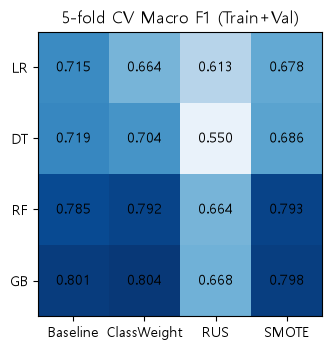

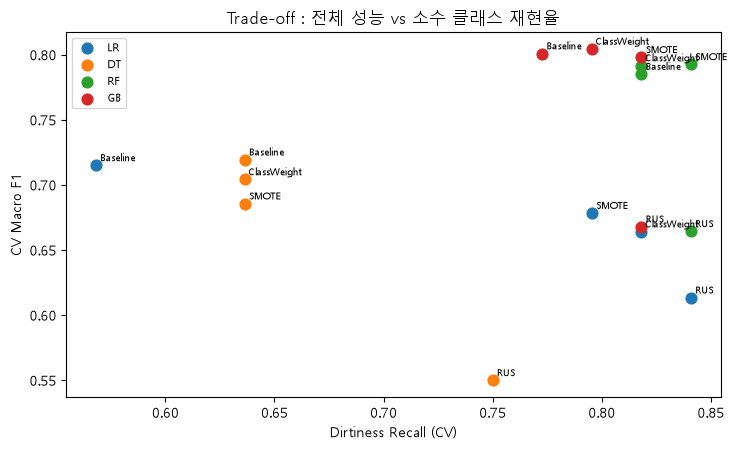

In [26]:
# 그림 1 : CV 히트맵
fig, ax = plt.subplots(figsize=(7, 3.6))
im = ax.imshow(cv_pv.values, cmap="Blues", vmin=cv_pv.values.min() - 0.02, vmax=cv_pv.values.max() + 0.01)
ax.set_xticks(range(len(METHODS))); ax.set_xticklabels(METHODS)
ax.set_yticks(range(len(MODEL_NAMES))); ax.set_yticklabels(MODEL_NAMES)
for i in range(cv_pv.shape[0]):
    for j in range(cv_pv.shape[1]):
        ax.text(j, i, f"{cv_pv.values[i, j]:.3f}", ha="center", va="center")
ax.set_title("5-fold CV Macro F1 (Train+Val)")
plt.tight_layout(); plt.savefig("d4_cv.png", dpi=120); plt.show()

# 그림 2 : Trade-off  (전체 성능 vs 소수 클래스 Dirtiness 찾는 능력)
fig, ax = plt.subplots(figsize=(7.5, 4.6))
for mn in MODEL_NAMES:
    s = cv[cv["모델"] == mn]
    ax.scatter(s["Dirtiness Recall"], s["CV Macro F1"], label=mn, s=60)
    for _, r in s.iterrows():
        ax.annotate(r["방법"], (r["Dirtiness Recall"], r["CV Macro F1"]), fontsize=7,
                    xytext=(3, 3), textcoords="offset points")
ax.set_xlabel("Dirtiness Recall (CV)"); ax.set_ylabel("CV Macro F1")
ax.set_title("Trade-off : 전체 성능 vs 소수 클래스 재현율")
ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig("d4_tradeoff.png", dpi=120); plt.show()

## 21. 모델 개선 - 하이퍼파라미터 튜닝
CV 점수가 가장 높은 조합 **1개**를 골라 설정값(하이퍼파라미터)을 바꿔 가며 다시 CV 로 비교함. 여러 개를 하고 싶으면 `TOP_N` 을 늘릴 것.

In [27]:
GRIDS = {"LR": {"C": [0.1, 1, 10]},
         "DT": {"max_depth": [None, 8, 12], "min_samples_leaf": [1, 3]},
         "RF": {"n_estimators": [300], "min_samples_leaf": [1, 2], "max_depth": [None, 15]},
         "GB": {"n_estimators": [100, 200], "learning_rate": [0.05, 0.1]}}
TOP_N = 1

top = cv.sort_values("CV Macro F1", ascending=False).head(TOP_N)
print("튜닝 대상 :", [(r["모델"], r["방법"], round(r["CV Macro F1"], 4)) for _, r in top.iterrows()])

tuned = []
for _, r0 in top.iterrows():
    for params in ParameterGrid(GRIDS[r0["모델"]]):
        r = cv_eval(r0["모델"], r0["방법"], params)
        r["파라미터"] = str(params)
        tuned.append(r)
        print(params, "->", round(r["CV Macro F1"], 4), flush=True)
tuned = pd.DataFrame(tuned).sort_values("CV Macro F1", ascending=False).reset_index(drop=True)
display(tuned[["모델", "방법", "파라미터", "CV Macro F1", "CV 표준편차", "Dirtiness Recall", "Pastry Recall"]].round(4))

튜닝 대상 : [('GB', 'ClassWeight', 0.8044)]
{'learning_rate': 0.05, 'n_estimators': 100} -> 0.7956
{'learning_rate': 0.05, 'n_estimators': 200} -> 0.8054
{'learning_rate': 0.1, 'n_estimators': 100} -> 0.8044
{'learning_rate': 0.1, 'n_estimators': 200} -> 0.8016


,모델,방법,파라미터,CV Macro F1,CV 표준편차,Dirtiness Recall,Pastry Recall
0,GB,ClassWeight,"{'learning_rate': 0.05, 'n_estimators': 200}",0.8054,0.0095,0.8182,0.7063
1,GB,ClassWeight,"{'learning_rate': 0.1, 'n_estimators': 100}",0.8044,0.0097,0.7955,0.6905
2,GB,ClassWeight,"{'learning_rate': 0.1, 'n_estimators': 200}",0.8016,0.0115,0.7955,0.6349
3,GB,ClassWeight,"{'learning_rate': 0.05, 'n_estimators': 100}",0.7956,0.0170,0.8182,0.7619


## 22. 최종 모델 + Test 평가
튜닝 1위 설정으로 **Train+Val 전체를 다시 학습**하고 Test 를 처음이자 마지막으로 평가함. 같은 모델의 처리 전(Baseline)과 나란히 비교.

In [28]:
fin = tuned.iloc[0]
fin_model, fin_method, fin_params = fin["모델"], fin["방법"], eval(fin["파라미터"])
print("최종 선택 :", fin_model, "+", fin_method, fin_params)

final = fit_model(build_p(fin_model, fin_method, fin_params), fin_model, fin_method, X_dev, y_dev)
base0 = fit_model(build_p(fin_model, "Baseline"), fin_model, "Baseline", X_dev, y_dev)   # 같은 모델 처리 전

pt_f, pt_b = final.predict(X_te), base0.predict(X_te)
cmp = pd.DataFrame({
    "구분": ["처리 전 (Baseline)", "최종 (처리+튜닝)"],
    "Test Macro F1": [f1_score(y_te, p, average="macro") for p in (pt_b, pt_f)],
    "Test Accuracy": [accuracy_score(y_te, p) for p in (pt_b, pt_f)]})
display(cmp.round(4))
print(classification_report(y_te, pt_f, target_names=CLASSES, digits=3))

최종 선택 : GB + ClassWeight {'learning_rate': 0.05, 'n_estimators': 200}


,구분,Test Macro F1,Test Accuracy
0,처리 전 (Baseline),0.8059,0.7918
1,최종 (처리+튜닝),0.8016,0.7635


              precision    recall  f1-score   support

       Bumps      0.675     0.691     0.683        81
   Dirtiness      0.909     0.909     0.909        11
   K_Scratch      0.973     0.910     0.940        78
Other_Faults      0.722     0.674     0.697       135
      Pastry      0.489     0.688     0.571        32
      Stains      0.923     0.857     0.889        14
   Z_Scratch      0.921     0.921     0.921        38

    accuracy                          0.763       389
   macro avg      0.802     0.807     0.802       389
weighted avg      0.775     0.763     0.767       389



## 23. 최종 모델 시각화

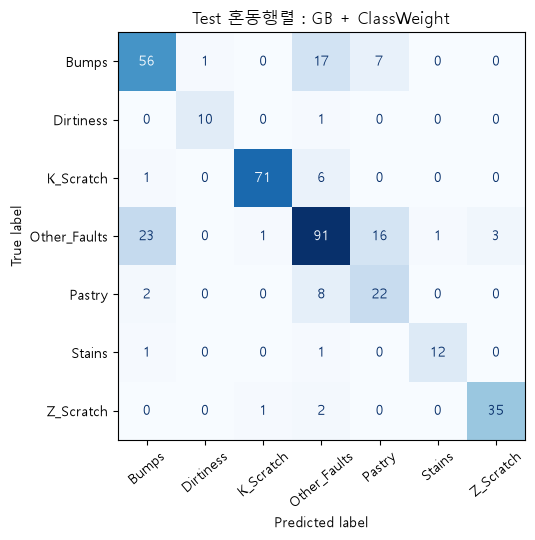

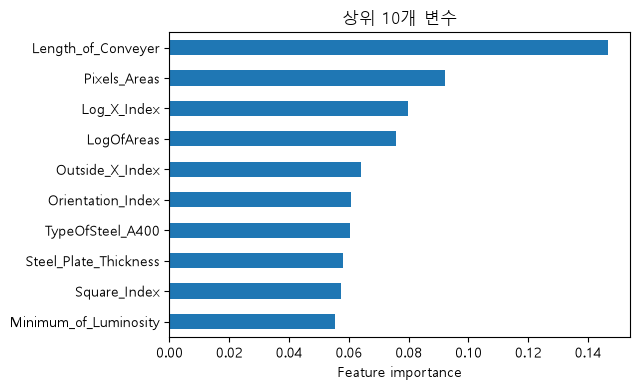

Length_of_Conveyer       0.1467
Pixels_Areas             0.0921
Log_X_Index              0.0797
LogOfAreas               0.0756
Outside_X_Index          0.0640
Orientation_Index        0.0606
TypeOfSteel_A400         0.0603
Steel_Plate_Thickness    0.0579
Square_Index             0.0573
Minimum_of_Luminosity    0.0554
dtype: float64

In [29]:
# 혼동행렬
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ConfusionMatrixDisplay(confusion_matrix(y_te, pt_f), display_labels=CLASSES).plot(
    ax=ax, xticks_rotation=40, colorbar=False, cmap="Blues")
ax.set_title(f"Test 혼동행렬 : {fin_model} + {fin_method}")
plt.tight_layout(); plt.savefig("d4_cm.png", dpi=120); plt.show()

# 변수 중요도 (트리 계열 모델일 때)
clf_final = final.named_steps["clf"]
if hasattr(clf_final, "feature_importances_"):
    names = [n.split("__", 1)[1] for n in final.named_steps["prep"].get_feature_names_out()]
    fi = pd.Series(clf_final.feature_importances_, index=names).sort_values(ascending=False).head(10)
    fi[::-1].plot(kind="barh", figsize=(6.5, 4))
    plt.xlabel("Feature importance"); plt.title("상위 10개 변수")
    plt.tight_layout(); plt.savefig("d4_fi.png", dpi=120); plt.show()
    display(fi.round(4))
else:
    print("이 모델은 변수 중요도(feature_importances_)가 없습니다 (LR 은 계수 사용).")

## 24. 대시보드 입력용 CSV 저장

In [30]:
cv.to_csv("cv_results.csv", index=False, encoding="utf-8-sig")
tuned.to_csv("tuning_results.csv", index=False, encoding="utf-8-sig")
cmp.to_csv("final_vs_baseline.csv", index=False, encoding="utf-8-sig")
pd.DataFrame(confusion_matrix(y_te, pt_f), index=CLASSES, columns=CLASSES).to_csv(
    "final_confusion_matrix.csv", encoding="utf-8-sig")
print("저장 완료 : cv_results.csv / tuning_results.csv / final_vs_baseline.csv / final_confusion_matrix.csv")

저장 완료 : cv_results.csv / tuning_results.csv / final_vs_baseline.csv / final_confusion_matrix.csv
